# NYC Yellow Taxi exploration — January 2026

This notebook is the readable, reproducible analysis. The reusable package owns feature engineering and filtering, so notebook and historical results use the same definitions.

Follow the workflow: inspect source → prepare features → inspect coverage → analyze time, trips, geography, money, and payments → describe limitations. Raw records are retained; each metric chooses its own subset.

In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve paths independently of whether Jupyter starts in the repo or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src/nyc_taxi").is_dir())
RAW = Path(os.environ.get("NYC_TAXI_RAW_DIR", str(Path.home() / "Data/raw/nyc-taxi")))
SUMMARY = Path(os.environ.get("NYC_TAXI_SUMMARY", str(Path.home() / "Data/processed/nyc-taxi/monthly_summary.parquet")))
FIGURES = ROOT / "reports/figures"


In [2]:
from nyc_taxi.pipeline import prepare_trips
from nyc_taxi.aggregation import aggregate_monthly_summary
from nyc_taxi.config import DEFAULT_CONFIG

YEAR, MONTH = 2026, 1
trip_file = RAW / f"yellow/{YEAR}/yellow_tripdata_{YEAR}-{MONTH:02d}.parquet"
zones = pd.read_csv(RAW / "taxi_zone_lookup.csv")
raw = pd.read_parquet(trip_file)
print(f"Raw shape: {raw.shape}; analytical configuration: {DEFAULT_CONFIG}")
display(raw.head())
display(raw.dtypes.to_frame("dtype"))

Raw shape: (3724889, 20); analytical configuration: AnalysisConfig(max_duration_min=120, max_distance_mi=60, max_speed_mph=60, monetary_alert_usd=500)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,7.2,1.00,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,7.9,4.25,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,10.7,4.25,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,38.7,1.00,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,13.5,1.00,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75


,dtype
VendorID,int32
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float64
trip_distance,float64
RatecodeID,float64
store_and_fwd_flag,str
PULocationID,int32
DOLocationID,int32
payment_type,int64


## 1. Inspect source quality

A missing passenger count does not make time or fare information unusable. `value_counts(dropna=False)` includes missing categories explicitly. Check patterns by vendor instead of assuming missing values are random.

In [3]:
display(raw.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
missing_passengers = raw["passenger_count"].isna()
display(pd.crosstab(raw["VendorID"], missing_passengers, normalize="index").mul(100))
display(raw["payment_type"].value_counts(dropna=False).sort_index())
print("Completely duplicated raw rows:", int(raw.duplicated().sum()))

,missing_count
Airport_fee,1088058
passenger_count,1088058
congestion_surcharge,1088058
RatecodeID,1088058
store_and_fwd_flag,1088058
VendorID,0
mta_tax,0
total_amount,0
improvement_surcharge,0
tolls_amount,0


passenger_count,False,True
VendorID,,
1,80.377098,19.622902
2,68.148443,31.851557
6,0.000000,100.000000
7,100.000000,0.000000


payment_type
0    1088058
1    2249747
2     314043
3      16641
4      56400
Name: count, dtype: int64

Completely duplicated raw rows: 0


In [4]:
df = prepare_trips(raw, zones, YEAR, MONTH)
monthly = aggregate_monthly_summary(df, YEAR, MONTH)
period = df["analysis_time_zone_payment"]
print("Prepared shape:", df.shape)
display(monthly.T)

Prepared shape: (3724889, 64)


,0
year,2.026000e+03
month,1.000000e+00
raw_record_count,3.724889e+06
trip_count,3.724882e+06
outside_period_count,7.000000e+00
duration_valid_count,3.675289e+06
median_duration_min,1.350000e+01
distance_valid_count,3.598765e+06
median_distance_mi,1.900000e+00
speed_valid_count,3.549552e+06


## 2. Understand filters and denominators

`valid_*` describes structural usability. `analysis_*` adds the month and analytical windows. Speed uses the same duration and distance windows as other trip metrics: 0–120 minutes, 0–60 miles, and 0–60 mph, with zero excluded.

The coverage below uses in-month records as the denominator. Unknown zones remain missing. `RatecodeID=99` is unknown, not a standard tariff. Passenger counts must be integers between 0 and 6; zero is retained as a reported source value.

In [5]:
names = ["duration", "distance", "speed", "monetary", "passenger", "ratecode"]
coverage = pd.DataFrame({"selected_records": [int(df[f"analysis_{n}"].sum()) for n in names]}, index=names)
coverage["coverage_pct"] = coverage.selected_records / int(period.sum()) * 100
display(coverage)
display(df.filter(regex="^valid_|^ratecode_known$").apply(lambda s: s.value_counts(dropna=False)))

,selected_records,coverage_pct
duration,3675289,98.668602
distance,3598765,96.614201
speed,3549552,95.293005
monetary,3684858,98.925496
passenger,2636817,70.789276
ratecode,2525960,67.813155


,valid_analysis_period,valid_duration,valid_distance,valid_speed,valid_fare_amount,valid_total_amount,valid_tip_amount,valid_monetary,valid_passenger_count,valid_payment_type,ratecode_known,valid_ratecode
False,7.0,45070.0,125738.0,170851.0,39463.0,39984.0,67.0,40025.0,7,NaN,1198922.0,<NA>
True,3724882.0,3679819.0,3599151.0,3554038.0,3685426.0,3684905.0,3724822.0,3684864.0,2636824,3724889.0,2525967.0,2525967
<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1088058,NaN,NaN,1198922


## 3. Trip distributions

Medians describe the middle record of each selected distribution. Each distribution has its own subset; their medians cannot be combined to reconstruct median speed. Histograms show the analytical windows rather than silently classifying every longer trip as an error.

duration {'count': 3675289.0, 'mean': 16.93535169615233, 'std': 13.374214677240184, 'min': 0.016666666666666666, '25%': 8.25, '50%': 13.5, '75%': 21.283333333333335, 'max': 120.0}
distance {'count': 3598765.0, 'mean': 3.48627481927828, 'std': 4.250707770732601, 'min': 0.01, '25%': 1.08, '50%': 1.9, '75%': 3.87, 'max': 59.91}


speed {'count': 3549552.0, 'mean': 11.147902994936116, 'std': 6.616262475665837, 'min': 0.00570884871550904, '25%': 7.012048192771084, '50%': 9.434944237918216, '75%': 13.147227533460804, 'max': 60.0}


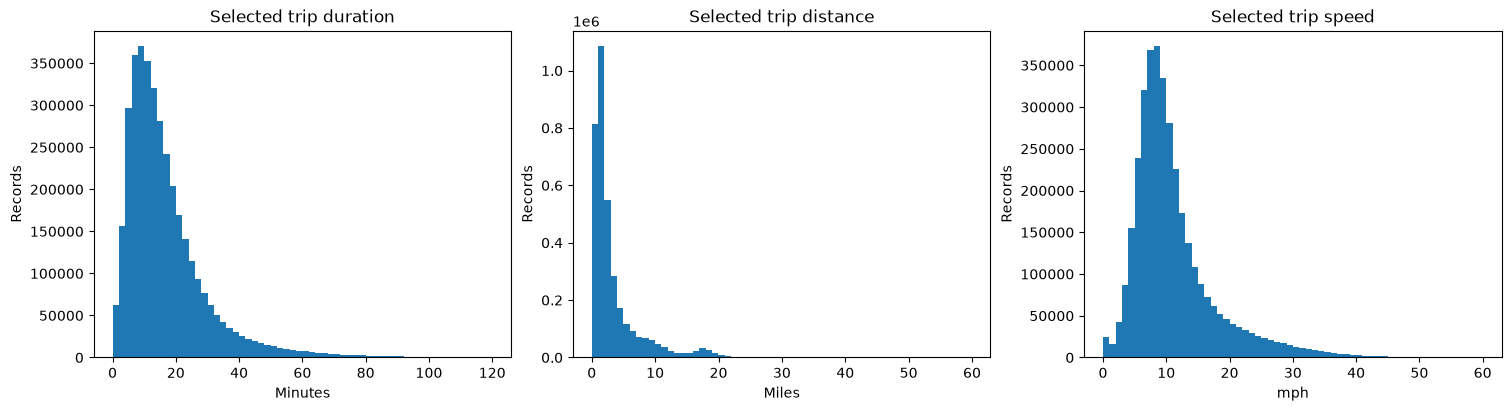

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for ax, name, column, unit in zip(axes, ["duration", "distance", "speed"],
        ["trip_duration_min", "trip_distance", "speed_mph"], ["Minutes", "Miles", "mph"]):
    values = df.loc[df[f"analysis_{name}"], column]
    values.plot.hist(bins=60, ax=ax)
    ax.set(title=f"Selected trip {name}", xlabel=unit, ylabel="Records")
    print(name, values.describe().to_dict())
plt.show()

In [7]:
display(df.loc[period].groupby("VendorID").agg(
    records=("VendorID", "size"), zero_duration=("trip_duration_min", lambda s: s.eq(0).sum()),
    zero_distance=("trip_distance", lambda s: s.eq(0).sum())))

,records,zero_duration,zero_distance
VendorID,,,
1,710425,322,9953
2,2965735,42,114960
6,4017,0,0
7,44705,44705,825


## 4. Time patterns

Use calendar dates to normalize day-of-week activity. Reindexing the full month makes missing dates visible instead of averaging only dates that happen to have records. Monthly activity is observed completed/reported activity, not unmet passenger demand.

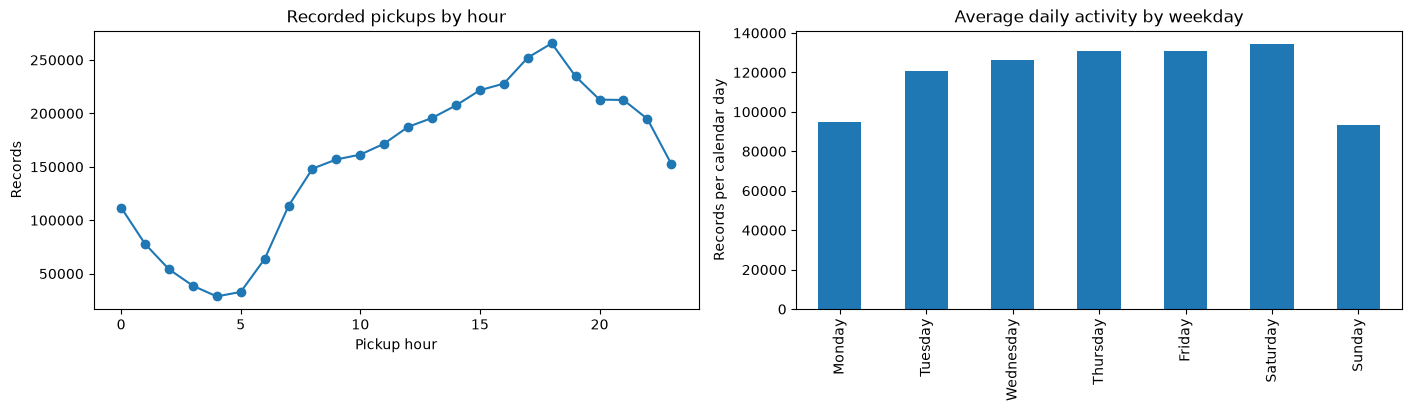

Monday        94859.00
Tuesday      120846.75
Wednesday    126418.00
Thursday     131068.60
Friday       131048.40
Saturday     134430.40
Sunday        93412.50
dtype: float64

In [8]:
start = pd.Timestamp(year=YEAR, month=MONTH, day=1)
calendar = pd.date_range(start, start + pd.offsets.MonthEnd(0), freq="D")
in_month = df.loc[period]
daily = in_month.groupby(in_month.tpep_pickup_datetime.dt.normalize()).size().reindex(calendar, fill_value=0)
weekday_average = daily.groupby(daily.index.dayofweek).mean().reindex(range(7))
weekday_average.index = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hourly = in_month.groupby("pickup_hour").size().reindex(range(24), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
hourly.plot(ax=axes[0], marker="o", title="Recorded pickups by hour", xlabel="Pickup hour", ylabel="Records")
weekday_average.plot.bar(ax=axes[1], title="Average daily activity by weekday", ylabel="Records per calendar day")
plt.show()
display(weekday_average)

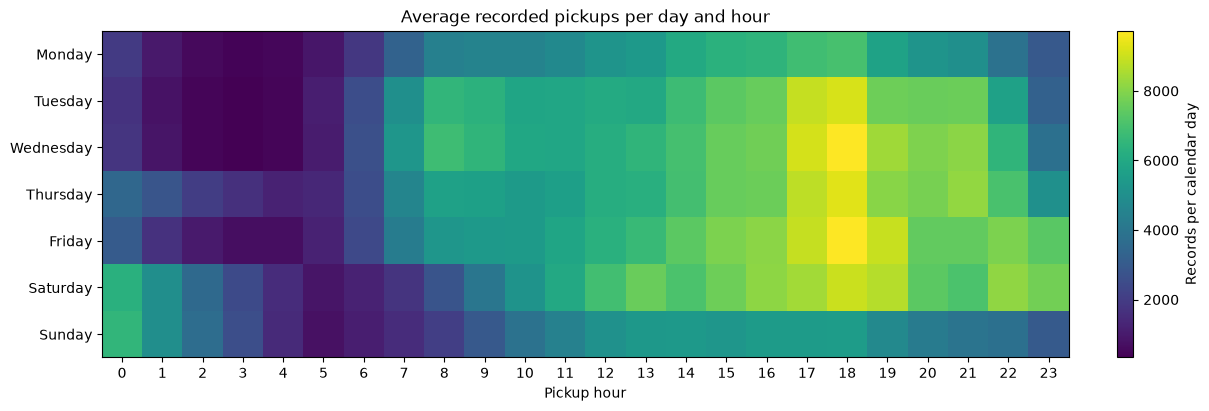

In [9]:
counts = in_month.groupby(["pickup_day_of_week", "pickup_hour"]).size().unstack(fill_value=0).reindex(index=range(7), columns=range(24), fill_value=0)
occurrences = pd.Series(calendar.dayofweek).value_counts().reindex(range(7))
average = counts.div(occurrences, axis=0)
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
image = ax.imshow(average, aspect="auto")
ax.set(xticks=range(24), yticks=range(7), yticklabels=weekday_average.index, xlabel="Pickup hour", title="Average recorded pickups per day and hour")
fig.colorbar(image, ax=ax, label="Records per calendar day")
plt.show()

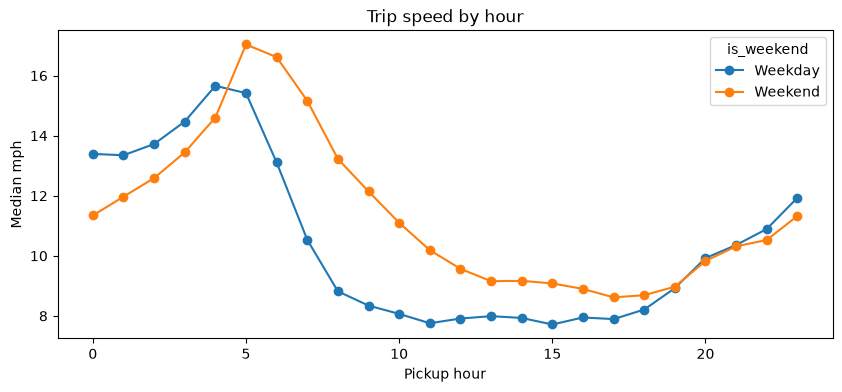

Pearson r across 24 hourly aggregates: -0.903


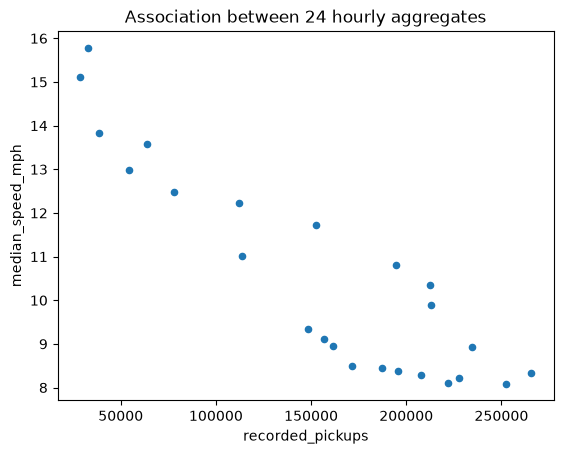

In [10]:
selected_speed = df.loc[df.analysis_speed]
speed_profile = selected_speed.groupby(["pickup_hour", "is_weekend"]).speed_mph.median().unstack().rename(columns={False: "Weekday", True: "Weekend"})
speed_profile.plot(figsize=(10, 4), marker="o", xlabel="Pickup hour", ylabel="Median mph", title="Trip speed by hour")
plt.show()
hourly_speed = selected_speed.groupby("pickup_hour").speed_mph.median().reindex(range(24))
hourly_profile = pd.DataFrame({"recorded_pickups": hourly, "median_speed_mph": hourly_speed})
correlation = hourly_profile.recorded_pickups.corr(hourly_profile.median_speed_mph)
print(f"Pearson r across 24 hourly aggregates: {correlation:.3f}")
hourly_profile.plot.scatter(x="recorded_pickups", y="median_speed_mph", title="Association between 24 hourly aggregates")
plt.show()

This association is descriptive. Time of day, route mix and day type can influence both measures. It is not a correlation across millions of individual trips and does not establish that taxi activity causes slower traffic.

## 5. Geography and airports

`same_zone` and airport indicators are missing when actual zones are unknown. Airport share below uses known pickup zones. Always display unknown counts alongside it; changes in missingness can alter the apparent trend.

,share_of_all_records_pct
PU_Borough,
Manhattan,85.388020
Queens,9.257287
Brooklyn,4.179139
Bronx,0.990260
Unknown,0.117883
Missing,0.041317
Staten Island,0.013047
EWR,0.013047


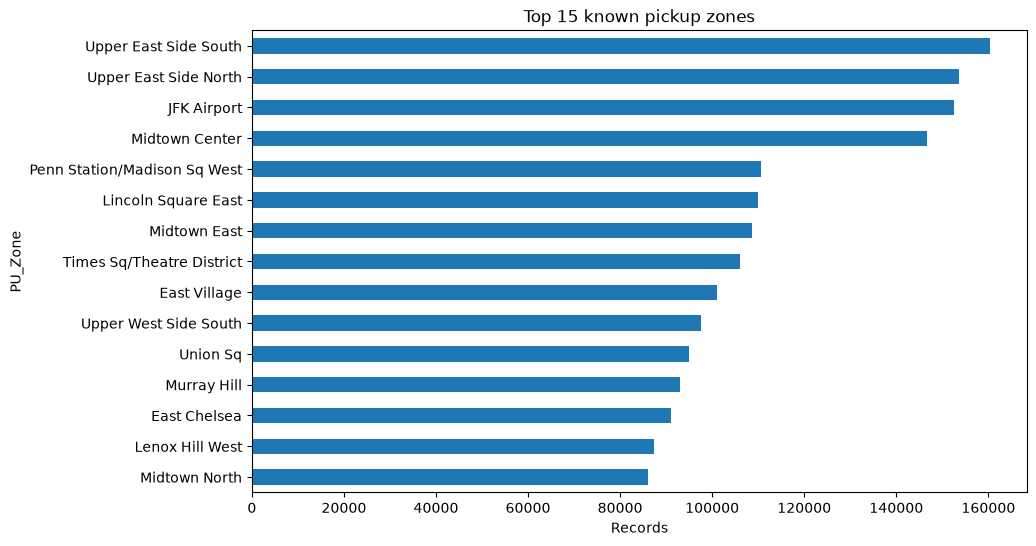

Unknown pickup zones: 5930
Airport share among known pickup zones: 6.40669737065711


same_zone
False    3525143
True      174490
<NA>       25249
Name: count, dtype: Int64

same_borough
True     3159473
False     540160
<NA>       25249
Name: count, dtype: Int64

In [11]:
display(in_month.PU_Borough.fillna("Missing").value_counts(normalize=True).mul(100).to_frame("share_of_all_records_pct"))
top_zones = in_month.groupby("PU_Zone").size().nlargest(15).sort_values()
top_zones.plot.barh(figsize=(10, 6), xlabel="Records", title="Top 15 known pickup zones")
plt.show()
print("Unknown pickup zones:", int(monthly.pickup_zone_unknown_count.iloc[0]))
print("Airport share among known pickup zones:", monthly.airport_pickup_share.iloc[0])
display(in_month.same_zone.value_counts(dropna=False))
display(in_month.same_borough.value_counts(dropna=False))

In [12]:
airport_rows = in_month.loc[in_month.airport_pickup.fillna(False)]
display(airport_rows.pickup_airport.value_counts().to_frame("records"))
display(pd.crosstab(airport_rows.pickup_airport, airport_rows.DO_Borough.fillna("Missing"), normalize="index").mul(100))
display(in_month.groupby(["PU_Zone", "DO_Zone"]).size().nlargest(15).to_frame("records"))

,records
pickup_airport,
JFK,152586
LGA,85190
EWR,486


DO_Borough,Bronx,Brooklyn,EWR,Manhattan,Missing,Queens,Staten Island,Unknown
pickup_airport,,,,,,,,
EWR,0.000000,0.000000,96.090535,2.057613,1.646091,0.000000,0.000000,0.205761
JFK,1.996907,18.592138,0.093062,44.656128,4.936233,29.481080,0.187435,0.057017
LGA,1.797159,12.733889,0.055171,70.674962,1.537739,13.084869,0.050475,0.065735


records
PU_Zone                      DO_Zone                           
Upper East Side South        Upper East Side North        24197
Upper East Side North        Upper East Side South        21055
                             Upper East Side North        17344
Upper East Side South        Upper East Side South        16185
Midtown Center               Upper East Side South        10380
Upper East Side South        Midtown Center                9541
Lincoln Square East          Upper West Side South         9065
Upper West Side South        Upper West Side North         8919
                             Lincoln Square East           8622
Midtown Center               Upper East Side North         8573
Lenox Hill West              Upper East Side North         8565
Upper East Side North        Lenox Hill West               8211
Upper East Side South        Lenox Hill West               7736
Upper East Side North        Midtown Center                7615
Penn Station/Madison Sq West Times Sq/Theatre District     7548

## 6. Monetary diagnostics

The selected sum excludes negative, nonfinite and inconsistent records. The signed sum keeps finite recorded totals with either sign. Neither is net driver/company revenue. Large positive amounts are flagged, not silently deleted; inspect their contribution before deciding on additional exclusions.

,0
monetary_valid_count,3.684858e+06
monetary_excluded_count,4.002400e+04
valid_monetary_total_amount_sum,1.098996e+08
finite_signed_total_amount_sum,1.086865e+08
excluded_monetary_total_amount_sum,-1.213096e+06
nonfinite_total_count,0.000000e+00
monetary_outlier_count,8.400000e+01
monetary_outlier_amount_sum,5.681783e+04
max_valid_total_amount,2.560200e+03


,VendorID,payment_type,fare_amount,tip_amount,total_amount,trip_distance,trip_duration_min
2127025,2,3,2555.2,0.0,2560.20,48.65,3525.700000
1230759,1,1,2500.0,0.0,2500.00,0.00,0.000000
1608067,2,3,990.0,0.0,991.00,0.00,0.083333
2167312,2,2,899.0,0.0,911.71,128.05,175.266667
2035988,2,4,900.0,0.0,904.25,9.03,24.883333
2153231,2,4,893.4,0.0,904.11,138.54,153.966667
84952,1,1,850.0,0.0,850.00,0.00,0.000000
1847335,2,2,837.4,0.0,838.90,121.18,133.883333
1586362,2,2,826.2,0.0,827.70,116.46,117.083333
2435631,2,4,800.3,0.0,807.55,13.92,1121.150000


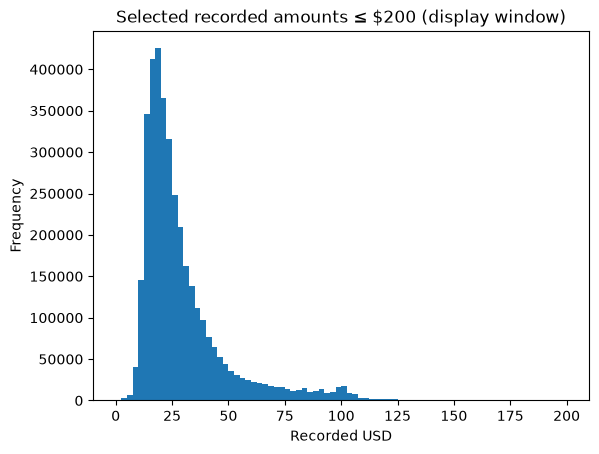

In [13]:
money_columns = ["monetary_valid_count", "monetary_excluded_count", "valid_monetary_total_amount_sum",
    "finite_signed_total_amount_sum", "excluded_monetary_total_amount_sum", "nonfinite_total_count",
    "monetary_outlier_count", "monetary_outlier_amount_sum", "max_valid_total_amount"]
display(monthly[money_columns].T)
display(in_month.nlargest(10, "total_amount")[["VendorID", "payment_type", "fare_amount", "tip_amount", "total_amount", "trip_distance", "trip_duration_min"]])
values = df.loc[df.analysis_monetary, "total_amount"]
values.loc[values.le(200)].plot.hist(bins=80, xlabel="Recorded USD", title="Selected recorded amounts ≤ $200 (display window)")
plt.show()

## 7. Passenger counts, payment categories and recorded tips

Flex Fare is a category of trips, not a directly observed card/cash choice. Codes 5 and 6 are unknown and voided. The non-Flex comparison explicitly includes only codes 1–4. Cash tips are absent from TLC's recorded tip field.

In [14]:
display(in_month.passenger_count.value_counts(dropna=False).sort_index())
display(df.loc[df.analysis_passenger].groupby("passenger_count")[["trip_distance", "trip_duration_min", "total_amount"]].median())
labels = {0: "Flex Fare", 1: "Credit card", 2: "Cash", 3: "No charge", 4: "Dispute", 5: "Unknown", 6: "Voided"}
payment_share = in_month.payment_type.value_counts(dropna=False, normalize=True).mul(100)
display(payment_share.rename(index=labels).to_frame("share_of_records_pct"))
display(in_month.groupby("payment_type")[["trip_distance", "trip_duration_min", "total_amount"]].median())
print("Card share of all in-month records:", monthly.credit_card_share.iloc[0])
print("Card share among non-Flex codes 1–4:", monthly.nonflex_credit_card_share.iloc[0])

passenger_count
0.0      14787
1.0    2150990
2.0     334367
3.0      72864
4.0      49738
5.0       9184
6.0       4887
7.0          2
8.0          4
9.0          1
NaN    1088058
Name: count, dtype: int64

,trip_distance,trip_duration_min,total_amount
passenger_count,,,
0.0,1.40,10.566667,19.800
1.0,1.62,12.000000,21.050
2.0,1.70,12.483333,21.840
3.0,1.65,12.416667,21.500
4.0,1.66,12.725000,22.750
5.0,1.63,11.141667,20.505
6.0,1.59,11.116667,20.220


,share_of_records_pct
payment_type,
Credit card,60.397725
Flex Fare,29.210536
Cash,8.430898
Dispute,1.514142
No charge,0.446699


,trip_distance,trip_duration_min,total_amount
payment_type,,,
0,2.40,16.000000,28.08
1,1.66,12.233333,21.90
2,1.50,11.316667,17.50
3,0.91,7.216667,10.55
4,1.49,11.150000,8.00


Card share of all in-month records: 60.39772535076279
Card share among non-Flex codes 1–4: 85.32021856597179


In [15]:
cards = df.loc[df.analysis_monetary & df.payment_type.eq(1) & df.effective_tip_rate.notna()]
print("Selected card records with meaningful pre-tip amount:", len(cards))
print("Positive recorded tip share:", cards.tip_amount.gt(0).mean() * 100)
print("Median effective recorded tip rate:", cards.effective_tip_rate.median())
display(cards.effective_tip_rate.round().value_counts(normalize=True).mul(100).head(10).to_frame("share_of_selected_card_records_pct"))

Selected card records with meaningful pre-tip amount: 2249463
Positive recorded tip share: 90.61793859245518
Median effective recorded tip rate: 20.0


,share_of_selected_card_records_pct
effective_tip_rate,
20.0,50.362909
0.0,9.564460
25.0,8.122205
15.0,4.118894
10.0,3.755563
30.0,3.224859
19.0,2.025861
12.0,1.656306
8.0,1.564196


## 8. Generated findings

These statements come from the calculations above. They describe January 2026 and should not be generalized to other seasons. Different metrics use different selected records.

In [16]:
row = monthly.iloc[0]
print(f"In-month recorded trips: {int(row.trip_count):,}; outside-month records: {int(row.outside_period_count):,}.")
print(f"Selected medians: {row.median_duration_min:.2f} min, {row.median_distance_mi:.2f} mi, {row.median_speed_mph:.2f} mph, ${row.median_total_amount:.2f}.")
print(f"Busiest pickup hour: {hourly.idxmax():02d}:00; busiest average weekday: {weekday_average.idxmax()}.")
print(f"Airport share among known pickup zones: {row.airport_pickup_share:.2f}%; card share of all records: {row.credit_card_share:.2f}%.")
print(f"Selected monetary sum: ${row.valid_monetary_total_amount_sum:,.2f}; finite signed sum: ${row.finite_signed_total_amount_sum:,.2f}.")

In-month recorded trips: 3,724,882; outside-month records: 7.
Selected medians: 13.50 min, 1.90 mi, 9.43 mph, $23.18.
Busiest pickup hour: 18:00; busiest average weekday: Saturday.
Airport share among known pickup zones: 6.41%; card share of all records: 60.40%.
Selected monetary sum: $109,899,580.12; finite signed sum: $108,686,483.69.
